# EventZilla · exploratory data analysis

**Purpose.** Before any dashboard or model is built, check what this data can and cannot answer for the four
business objectives of the project (GIMSI, `docs/GIMSI.md`):

| | Business objective | Question asked of the data |
|---|---|---|
| BO1 | Revenue and profitability | Where does confirmed revenue come from, and how does it move over time? |
| BO2 | Reservations and conversion | How many reservations are confirmed, cancelled or left pending, and what moves that? |
| BO3 | Satisfaction and retention | How do customers rate us, who complains, who comes back? |
| BO4 | Marketing return | Does marketing spend bring customers and revenue? |

**Data.** The star schema built by dbt (`marts`: one fact, `fact_reservation`, and its dimensions), the reporting
tables at other grains, the quality schema (quarantined rows) and, where the question is about the source,
`raw`. Everything is read from the warehouse, so the figures here are the figures the dashboards show.

**Method.** Inventory → data quality → one section per objective → statistical tests of the differences that
look interesting → implications for the dashboards and for the data-science objectives.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sqlalchemy import create_engine, text

# connection: environment, or the repository's .env (git-ignored)
env = Path("..") / ".env"
if env.exists():
    for line in env.read_text().splitlines():
        if "=" in line and not line.startswith("#"):
            k, v = line.split("=", 1)
            os.environ.setdefault(k, v)
url = (f"postgresql+psycopg2://{os.environ.get('WAREHOUSE_USER', 'eventzilla')}:{os.environ['WAREHOUSE_PASSWORD']}"
       f"@{os.environ.get('EVENTZILLA_DB_HOST', 'localhost')}:{os.environ.get('WAREHOUSE_PORT', '5442')}/eventzilla")
engine = create_engine(url)
q = lambda sql: pd.read_sql(text(sql), engine)  # noqa: E731

# house style: graphite ink, one orange signal, hairlines
INK, INK2, HAIR, SIGNAL = "#121212", "#5c5952", "#cdc9c0", "#ff4f00"
plt.rcParams.update({
    "figure.figsize": (10, 3.6), "figure.dpi": 110, "axes.edgecolor": HAIR, "axes.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": HAIR,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "xtick.color": INK2, "ytick.color": INK2,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left", "font.size": 9,
    "axes.prop_cycle": plt.cycler(color=[INK, SIGNAL, INK2, "#9d998f"]),
})
fmt_k = plt.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M" if abs(x) >= 1e6 else f"{x/1e3:.0f}k")

## 1 · Inventory: what is there, at which grain

In [2]:
inventory = q('''
select table_schema as schema, table_name as "table",
       (xpath('/row/n/text()', query_to_xml(format('select count(*) as n from %I.%I', table_schema, table_name),
                                            false, true, '')))[1]::text::int as rows
from information_schema.tables
where table_schema in ('marts', 'reporting', 'reference', 'quality')
order by 1, 2''')
inventory

,schema,table,rows
0,marts,dim_beneficiary,5000
1,marts,dim_date,1461
2,marts,dim_event,12000
3,marts,dim_geography,24
4,marts,dim_provider,800
5,marts,dim_service,2500
6,marts,fact_reservation,18000
7,quality,flagged_reservation_dates,8967
8,quality,flagged_traffic_days,6
9,quality,rejected_evaluations,312


In [3]:
coverage = q('''
select 'reservations (reservation_date)' as series, min(reservation_date), max(reservation_date) from marts.fact_reservation
union all select 'events (event_date)', min(event_date), max(event_date) from marts.dim_event
union all select 'site traffic', min(traffic_date), max(traffic_date) from reporting.rpt_site_traffic_daily
union all select 'marketing spend', min(month_start), max(month_start) from reporting.rpt_marketing_monthly''')
coverage

,series,min,max
0,reservations (reservation_date),2022-01-01,2025-12-31
1,events (event_date),2022-01-01,2025-12-31
2,site traffic,2022-01-01,2022-12-31
3,marketing spend,2023-01-01,2024-12-01


**Reading.** One fact at the reservation grain (18,000 rows) and six dimensions. Reservations and events cover
the same four years, 2022-2025. The two reporting series do **not**: site traffic covers 2022 only and marketing
spend 2023-01 to 2024-12 (24 valid months). Any chart that crosses them must say which years it uses.

## 2 · Data quality: what the source gets wrong

In [4]:
dq = q('''
select 'evaluations with a rating outside 1-5' as rule, count(*) as rows, (select count(*) from raw.evaluation) as of_rows
from quality.rejected_evaluations
union all select 'marketing rows that are not a calendar month', count(*), (select count(*) from raw.marketing_spend)
from quality.rejected_marketing_months
union all select 'reservations dated after their own event', count(*), (select count(*) from marts.fact_reservation)
from quality.flagged_reservation_dates
union all select 'services without a list price', count(*) filter (where list_price is null), count(*) from marts.dim_service
union all select 'events without a budget', count(*) filter (where budget is null), count(*) from marts.dim_event
union all select 'website days with more reservations than visitors', count(*), 365 from quality.flagged_traffic_days''')
dq["share"] = (dq["rows"] / dq["of_rows"]).map("{:.1%}".format)
dq

,rule,rows,of_rows,share
0,evaluations with a rating outside 1-5,312,12000,2.6%
1,marketing rows that are not a calendar month,12,36,33.3%
2,reservations dated after their own event,8967,18000,49.8%
3,services without a list price,214,2500,8.6%
4,events without a budget,948,12000,7.9%
5,website days with more reservations than visitors,6,365,1.6%


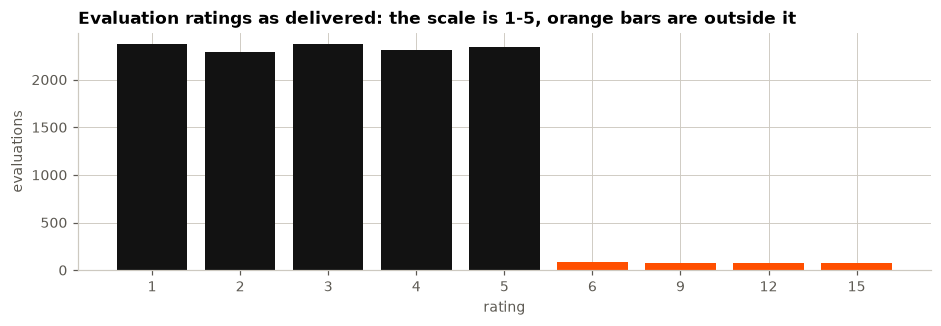

In [5]:
fig, ax = plt.subplots(figsize=(10, 2.8))
r = q("select rating, count(*) n from raw.evaluation group by 1 order by rating::int")
r["valid"] = r["rating"].astype(int).between(1, 5)
ax.bar(r["rating"], r["n"], color=[INK if v else SIGNAL for v in r["valid"]])
ax.set_title("Evaluation ratings as delivered: the scale is 1-5, orange bars are outside it")
ax.set_xlabel("rating"); ax.set_ylabel("evaluations");

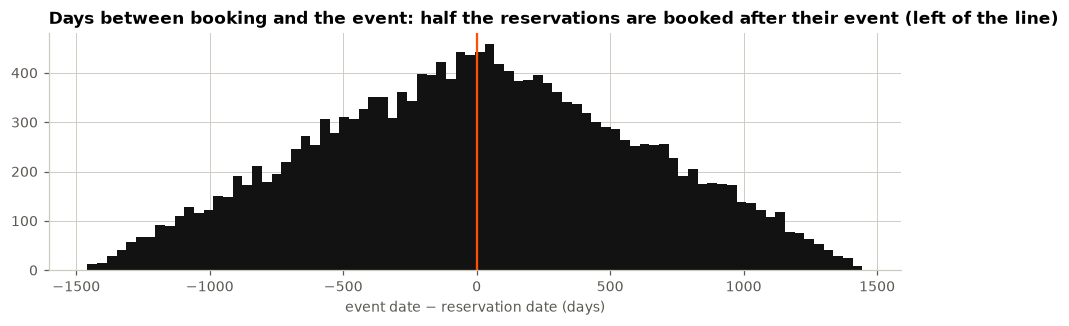

In [6]:
lead = q("select lead_time_days from marts.fact_reservation")
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.hist(lead["lead_time_days"], bins=80, color=INK)
ax.axvline(0, color=SIGNAL, lw=1.5)
ax.set_title("Days between booking and the event: half the reservations are booked after their event (left of the line)")
ax.set_xlabel("event date − reservation date (days)");

**Reading.**
- Ratings of 6, 9, 12 and 15 are multiples of 3 above the scale: most likely a units or scaling error at the
  source, not real opinions. They are quarantined (`quality.rejected_evaluations`) and left out of every average.
- Half the reservations are dated after their event, and the lead time is spread almost evenly from about -4 to
  +4 years. Reservation and event dates were generated independently, so **lead time cannot support any
  decision** on this dataset; it is kept as a column, flagged, and absent from the dashboards.
- Missing list prices (9 %) and budgets (8 %) are left missing, never imputed: an imputed price would show up
  as revenue nobody earned.
- Six days of website traffic record more reservations than visitors, which a funnel cannot do. They are
  flagged and their conversion left empty; the dashboards use the median conversion, which these outliers
  would otherwise distort (mean 13.6 % against a median of 5.5 % before the rule).

## 3 · Is there signal? A test of the data-generating process

In [7]:
f = q('''select f.*, e.event_type, e.budget, s.service_category, g.region
         from marts.fact_reservation f
         join marts.dim_event e using (event_id)
         join marts.dim_service s using (service_id)
         join marts.dim_geography g using (governorate_id)''')
tests = []
for factor in ["event_type", "service_category", "region"]:
    ct = pd.crosstab(f[factor], f["status"])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    tests.append({"question": f"is the status mix different by {factor}?", "test": "chi-square",
                  "p_value": p, "effect": f"Cramér's V = {v:.3f}"})
    groups = [g["final_price"].values for _, g in f.groupby(factor)]
    h, p = stats.kruskal(*groups)
    tests.append({"question": f"are prices different by {factor}?", "test": "Kruskal-Wallis",
                  "p_value": p, "effect": f"H = {h:.1f}"})
rho, p = stats.spearmanr(f["final_price"], f["list_price"], nan_policy="omit")
tests.append({"question": "does the agreed price follow the list price?", "test": "Spearman",
              "p_value": p, "effect": f"rho = {rho:.3f}"})
rho, p = stats.spearmanr(f["final_price"], f["budget"], nan_policy="omit")
tests.append({"question": "do bigger budgets mean bigger bookings?", "test": "Spearman",
              "p_value": p, "effect": f"rho = {rho:.3f}"})
pd.DataFrame(tests).style.format({"p_value": "{:.3f}"})

,question,test,p_value,effect
0,is the status mix different by event_type?,chi-square,0.414,Cramér's V = 0.013
1,are prices different by event_type?,Kruskal-Wallis,0.458,H = 2.6
2,is the status mix different by service_category?,chi-square,0.472,Cramér's V = 0.012
3,are prices different by service_category?,Kruskal-Wallis,0.101,H = 6.2
4,is the status mix different by region?,chi-square,0.709,Cramér's V = 0.014
5,are prices different by region?,Kruskal-Wallis,0.570,H = 3.9
6,does the agreed price follow the list price?,Spearman,0.671,rho = 0.003
7,do bigger budgets mean bigger bookings?,Spearman,0.083,rho = 0.013


**Reading, and the most important finding of this EDA.** The columns behave as if drawn independently:
status mix, prices and their links to list price or budget show effects that are tiny or indistinguishable
from noise. The dataset is **synthetic** (generated names, `example.com` addresses), and its generator did not
encode business relationships.

What follows from it:
- The dashboards describe **this dataset**; they must not present differences between groups as market facts,
  and they show the scale of a difference next to the difference.
- The data-science objectives are judged **against naive baselines**. A model that cannot beat the baseline on
  random data is the honest result, and it is reported as such.

## 4 · BO1 · Revenue and profitability

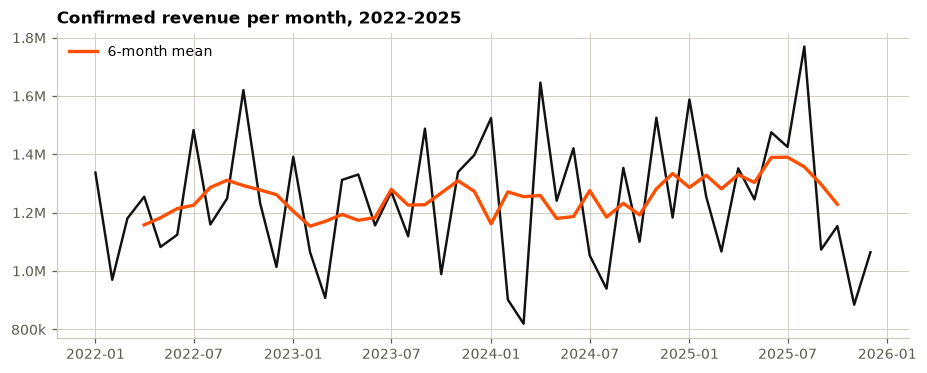

In [8]:
m = q('''select date_trunc('month', reservation_date)::date as month, sum(revenue) as revenue,
                count(*) filter (where is_confirmed) as confirmed
         from marts.fact_reservation group by 1 order by 1''')
fig, ax = plt.subplots()
ax.plot(m["month"], m["revenue"], color=INK, lw=1.6)
ax.plot(m["month"], m["revenue"].rolling(6, center=True).mean(), color=SIGNAL, lw=2.2, label="6-month mean")
ax.yaxis.set_major_formatter(fmt_k); ax.legend(frameon=False)
ax.set_title("Confirmed revenue per month, 2022-2025");

In [9]:
total = f["revenue"].sum()
by = (f[f.is_confirmed].groupby("event_type")["revenue"].agg(["sum", "count", "mean"])
      .assign(share=lambda d: d["sum"] / total).sort_values("sum", ascending=False))
by.style.format({"sum": "{:,.0f}", "mean": "{:,.0f}", "share": "{:.1%}"})

,sum,count,mean,share
event_type,,,,
Wedding,"15,892,996",1542,"10,307",26.7%
Corporate Event,"14,912,676",1518,"9,824",25.0%
Birthday,"14,819,433",1513,"9,795",24.9%
Private Party,"13,911,566",1451,"9,588",23.4%


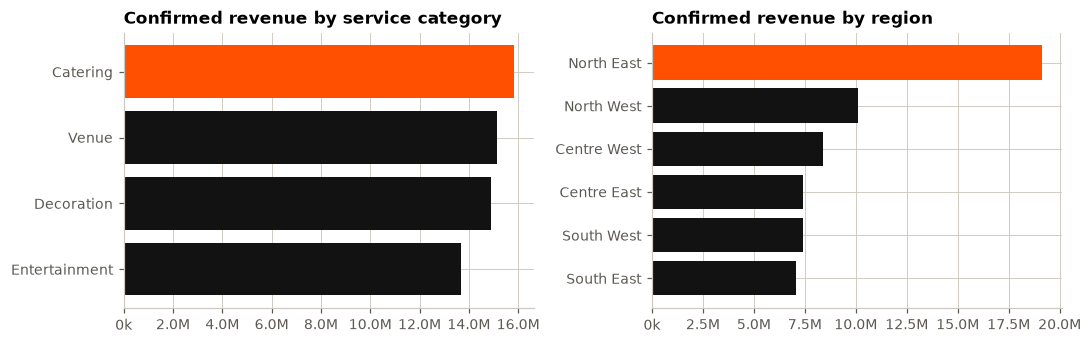

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, col in zip(axes, ["service_category", "region"]):
    s = f.groupby(col)["revenue"].sum().sort_values()
    ax.barh(s.index, s.values, color=[SIGNAL if i == len(s) - 1 else INK for i in range(len(s))])
    ax.xaxis.set_major_formatter(fmt_k); ax.set_title(f"Confirmed revenue by {col.replace('_', ' ')}")
fig.tight_layout()

In [11]:
reg = f.groupby("region").agg(revenue=("revenue", "sum"), reservations=("reservation_id", "count"))
reg = reg.join(q("select region, sum(population_2024) pop from marts.dim_geography group by 1").set_index("region"))
reg["revenue_per_1000_inhabitants"] = reg["revenue"] / reg["pop"] * 1000
reg.sort_values("revenue", ascending=False).style.format("{:,.0f}")

,revenue,reservations,pop,revenue_per_1000_inhabitants
region,,,,
North East,"19,155,831","6,028","4,556,665","4,204"
North West,"10,091,988","3,062","1,169,697","8,628"
Centre West,"8,410,982","2,313","1,583,535","5,312"
Centre East,"7,419,337","2,337","2,859,503","2,595"
South West,"7,390,130","1,956","692,013","10,679"
South East,"7,068,403","2,304","1,110,756","6,364"


**Reading.** Revenue is flat across the four years (14.7M to 15.4M a year) with month-to-month noise and no
clear seasonal shape. Weddings bring the most confirmed revenue (26.7 %) and private parties the least
(23.4 %), a spread in line with their volumes. By region, the North East leads in absolute revenue (19.2M) because
it holds the most providers, but per inhabitant it is fifth of six (4,204 per 1,000 inhabitants) and the South
West first (10,679): the per-inhabitant view is the one to use when deciding where to recruit providers.

## 5 · BO2 · Reservations and conversion

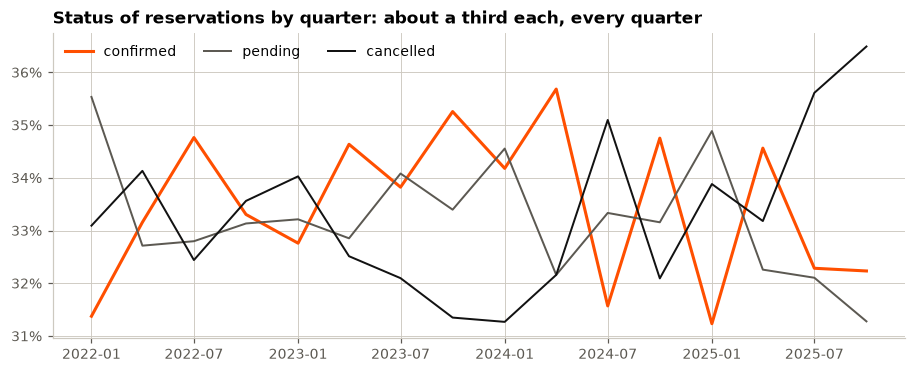

In [12]:
st = q('''select date_trunc('quarter', reservation_date)::date as quarter, status, count(*) n
          from marts.fact_reservation group by 1, 2''').pivot(index="quarter", columns="status", values="n")
share = st.div(st.sum(axis=1), axis=0)
fig, ax = plt.subplots()
for col, color in [("confirmed", SIGNAL), ("pending", INK2), ("cancelled", INK)]:
    ax.plot(share.index, share[col], label=col, color=color, lw=2 if col == "confirmed" else 1.3)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}")); ax.legend(frameon=False, ncol=3)
ax.set_title("Status of reservations by quarter: about a third each, every quarter");

In [13]:
days = q('''select d.date_day, d.is_ramadan, d.is_holiday, d.is_weekend, d.season,
                   count(f.reservation_id) as reservations, coalesce(sum(f.revenue), 0) as revenue
            from marts.dim_date d left join marts.fact_reservation f on f.reservation_date = d.date_day
            group by 1, 2, 3, 4, 5''')
rows = []
for flag in ["is_ramadan", "is_holiday", "is_weekend"]:
    a, b = days[days[flag]]["revenue"], days[~days[flag]]["revenue"]
    u, p = stats.mannwhitneyu(a, b)
    rows.append({"days": flag.removeprefix("is_"), "n_days": len(a), "revenue_per_day": a.mean(),
                 "other_days": b.mean(), "difference": a.mean() / b.mean() - 1, "p_value": p})
pd.DataFrame(rows).style.format({"revenue_per_day": "{:,.0f}", "other_days": "{:,.0f}",
                                 "difference": "{:+.1%}", "p_value": "{:.3f}"})

,days,n_days,revenue_per_day,other_days,difference,p_value
0,ramadan,118,"36,457","41,128",-11.4%,0.103
1,holiday,60,"36,825","40,919",-10.0%,0.145
2,weekend,418,"40,325","40,921",-1.5%,0.759


,visitors,reservations,conversion_rate
mean,2784.073973,143.989041,0.105963
50%,2505.000000,143.000000,0.054000
min,58.000000,0.000000,0.000000
max,22215.000000,300.000000,1.000000


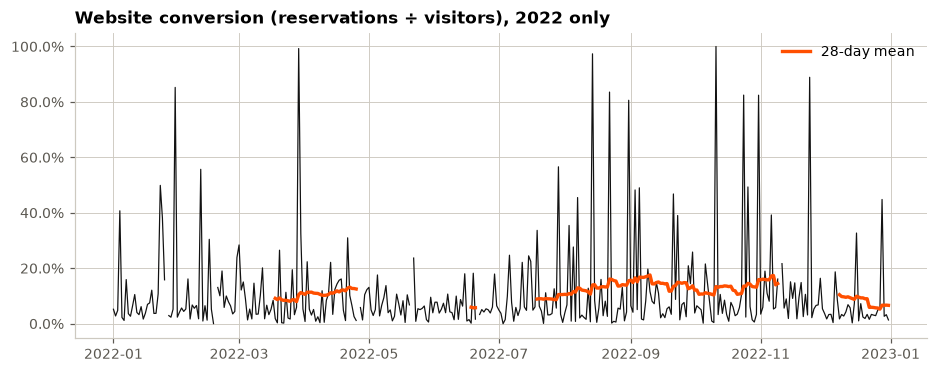

In [14]:
funnel = q("select traffic_date, visitors, reservations, conversion_rate from reporting.rpt_site_traffic_daily")
fig, ax = plt.subplots()
ax.plot(funnel["traffic_date"], funnel["conversion_rate"], color=INK, lw=0.8)
ax.plot(funnel["traffic_date"], funnel["conversion_rate"].rolling(28).mean(), color=SIGNAL, lw=2.2,
        label="28-day mean")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.1%}")); ax.legend(frameon=False)
ax.set_title("Website conversion (reservations ÷ visitors), 2022 only");
funnel[["visitors", "reservations", "conversion_rate"]].describe().loc[["mean", "50%", "min", "max"]]

**Reading.** Confirmation, cancellation and pending each hold a third of reservations in every quarter. Revenue
per day is 11 % lower during Ramadan and 10 % lower on public holidays, but neither difference is significant
(p = 0.10 and 0.15); weekends are flat (-1.5 %). The dashboards may show these figures, labelled as not
significant. The 2022 website funnel is the only series that can carry the pitch's "+15 % reservation rate"
target, and only for 2022: its median conversion is the baseline.

## 6 · BO3 · Satisfaction and retention

In [15]:
rt = f.dropna(subset=["rating_avg"])
print(f"reservations with at least one valid evaluation: {len(rt):,} of {len(f):,} ({len(rt)/len(f):.0%})")
print(f"mean rating {rt.rating_avg.mean():.2f} / 5 · share rated 4 or more: {(rt.rating_avg >= 4).mean():.0%}")
rt.groupby("service_category")["rating_avg"].agg(["mean", "count"]).round(2)

reservations with at least one valid evaluation: 8,631 of 18,000 (48%)
mean rating 2.99 / 5 · share rated 4 or more: 35%


,mean,count
service_category,,
Catering,2.98,2196
Decoration,2.97,2172
Entertainment,3.00,2066
Venue,3.00,2197


In [16]:
c = q('''select p.region, sum(c.complaints) complaints from reporting.rpt_complaint_summary c
         join marts.dim_provider dp using (provider_id) join marts.dim_geography p on p.governorate_id = lower(translate(dp.city,
         'ÀÂÄÉÈÊËÎÏÔÖÙÛÜÇàâäéèêëîïôöùûüç', 'AAAEEEEIIOOUUUCaaaeeeeiioouuuc')) group by 1''').set_index("region")
c = c.join(f.groupby("region")["reservation_id"].count().rename("reservations"))
c["complaints_per_100_reservations"] = c["complaints"] / c["reservations"] * 100
subjects = q("select subject, status, sum(complaints) n from reporting.rpt_complaint_summary group by 1, 2")
display(c.sort_values("complaints_per_100_reservations", ascending=False).round(1))
subjects.pivot(index="subject", columns="status", values="n")

,complaints,reservations,complaints_per_100_reservations
region,,,
North West,475.0,3062,15.5
Centre West,332.0,2313,14.4
South East,319.0,2304,13.8
Centre East,317.0,2337,13.6
North East,799.0,6028,13.3
South West,258.0,1956,13.2


status,closed,open
subject,,
Billing Issue,313.0,316.0
Late Delivery,302.0,328.0
Product Defect,301.0,305.0
Service Quality,324.0,311.0


In [17]:
b = q("select events, is_returning, complaints from marts.dim_beneficiary")
active = b[b.events > 0]
print(f"customers with at least one event: {len(active):,} · returning (2+ events): {active.is_returning.mean():.0%}")
print(f"complaints among returning vs one-time customers: "
      f"{active[active.is_returning].complaints.mean():.2f} vs {active[~active.is_returning].complaints.mean():.2f} per customer")

customers with at least one event: 4,557 · returning (2+ events): 76%
complaints among returning vs one-time customers: 0.50 vs 0.50 per customer


**Reading.** 48 % of reservations were evaluated, so the satisfaction indicators are computed on that
population and say so. The mean rating is 2.99 out of 5 (35 % of evaluated reservations score 4 or more) and
barely moves by category (2.97 to 3.00). 76 % of active customers have organised two or more events: that is
the baseline for the retention target (+20 %). Complaints run at 13.2 to 15.5 per 100 reservations by region,
highest in the North West, and are split evenly across the four subjects and between open and closed.

## 7 · BO4 · Marketing return

spend vs revenue same month rho=-0.19 (p=0.37); next month rho=-0.24 (p=0.26)
spend vs new customers rho=0.18 (p=0.40)


,months,spend,new_customers,mean_of_monthly_ratios,cost_per_new_customer
spend_type,,,,,
cheap,5,35489.0,3860,32.7,9.2
normal,12,204476.0,14073,19.5,14.5
expensive,7,346624.0,8262,63.8,42.0


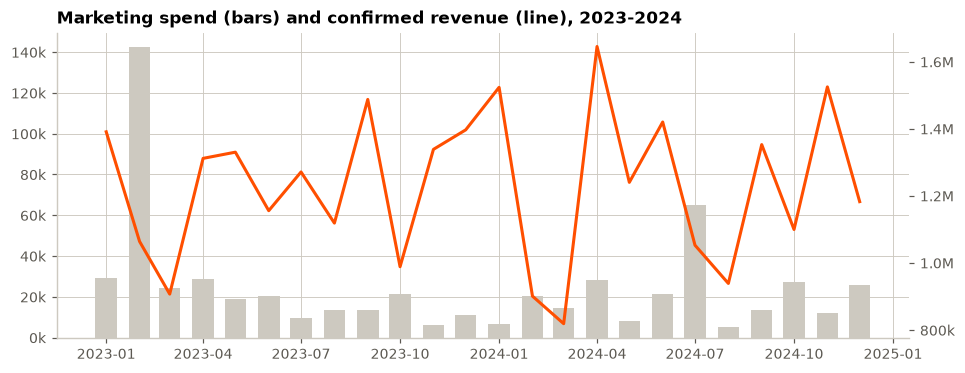

In [18]:
mk = q("select * from reporting.rpt_marketing_monthly order by month_start")
fig, ax = plt.subplots()
ax.bar(mk["month_start"], mk["marketing_spend"], width=20, color=HAIR, label="marketing spend")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(mk["month_start"], mk["confirmed_revenue"], color=SIGNAL, lw=2, label="confirmed revenue")
ax.yaxis.set_major_formatter(fmt_k); ax2.yaxis.set_major_formatter(fmt_k)
ax.set_title("Marketing spend (bars) and confirmed revenue (line), 2023-2024")
rho_now, p_now = stats.spearmanr(mk["marketing_spend"], mk["confirmed_revenue"])
rho_lag, p_lag = stats.spearmanr(mk["marketing_spend"][:-1], mk["confirmed_revenue"][1:].values)
rho_new, p_new = stats.spearmanr(mk["marketing_spend"], mk["new_beneficiaries"])
print(f"spend vs revenue same month rho={rho_now:.2f} (p={p_now:.2f}); next month rho={rho_lag:.2f} (p={p_lag:.2f})")
print(f"spend vs new customers rho={rho_new:.2f} (p={p_new:.2f})")
by_level = mk.groupby("spend_type").agg(months=("month_start", "size"), spend=("marketing_spend", "sum"),
                                        new_customers=("new_beneficiaries", "sum"),
                                        mean_of_monthly_ratios=("cost_per_new_beneficiary", "mean"))
by_level["cost_per_new_customer"] = by_level["spend"] / by_level["new_customers"]
by_level.round(1).sort_values("cost_per_new_customer")

**Reading.** Over the 24 valid months, spend shows no significant link to revenue, in the same month
(rho = -0.19, p = 0.37) or the next (rho = -0.24, p = 0.26), nor to new customers (rho = 0.18, p = 0.40). Cost
per new customer is the indicator a marketing manager can act on. Pooled over each spend level (total spend
divided by total new customers, the definition Metabase and the application use), cheap months recruit at 9.2
per new customer, normal months at 14.5 and expensive months at 42.0, more than four times the cheap cost.
Averaging the monthly ratios instead (32.7, 19.5 and 63.8) over-weights the few months with very few new
customers and even reverses cheap and normal: the pooled figure is the one to decide on.

## 8 · Conclusions for the dashboards and the data-science objectives

**For the dashboards (Metabase and the application):**
1. Lead with the levels that are solid: confirmed revenue, reservations by status, ratings, complaints,
   returning customers, cost per new customer.
2. Show differences between groups with their scale, and avoid causal wording: on this dataset most of them are
   noise.
3. Say which years each series covers (site traffic: 2022; marketing: 2023-2024).
4. Never use lead time; show the quality layer (rows quarantined, and why) so users can see what was excluded.

**For the data-science objectives (`docs/GIMSI.md`):**
1. *Revenue forecast* (BO1): 48 monthly points, flat with noise. Judge any model against the naive and seasonal
   naive forecasts with the team's gate (SMAPE < 30 %, MASE < 1); expect the naive baseline to be hard to beat.
2. *Confirmation prediction* (BO2): the status looks independent of the available features; expect AUC near
   0.5 and report it.
3. *Customer segmentation* (BO3, BO4): segments from behaviour (events, spend, complaints) are descriptive and
   still useful for targeting, even when no feature predicts status.

The honest outcome is part of the deliverable: knowing that a model cannot beat a baseline on this data is a
result, and it prevents a dashboard or a pitch from promising what the data cannot show.